<a href="https://colab.research.google.com/github/PioPio31/AnaliticaDeDatos_Equipo1/blob/main/Practica3_U3/Practica_3_Valdez_Escobedo_Montserrat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Series de tiempo**

# **Datos Alumno**

# **Nombre**: Valdez Escobedo Montserrat
# **No control**: 23111475

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia APPLE.**

# **0 - Preparando los datos ORIGINALES**

In [71]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [72]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [73]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [74]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'AAPL'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [75]:
data.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-11-15,146.407990,148.242974,145.851632,146.769124,59222800
2021-11-16,147.384018,147.862289,145.763766,146.349404,59256200
2021-11-17,149.814392,151.288227,147.374259,147.384015,88807000
2021-11-18,154.089478,154.870323,149.384910,150.029109,137827700
2021-11-19,156.705307,157.164053,152.781570,153.874744,117305600


**NOTA: Las variables significan:**
*   Date:	Fecha en la que se registraron los datos bursátiles.
*   Close:	Precio al que cerró la acción al finalizar la jornada.
*   High:	Precio más alto que alcanzó la acción durante el día.
*   Low:	Precio más bajo que alcanzó la acción durante el día.
*   Open:	Precio de la acción al comenzar la jornada.
*   Volume:	Cantidad de acciones que se negociaron durante ese día.

In [76]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path, header=2)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
df.columns=['Date','Close','High','Low','Open','Volume'] #Se agrega columna Date
df.head()

,Date,Close,High,Low,Open,Volume
0,2021-11-15,146.407990,148.242974,145.851632,146.769124,59222800
1,2021-11-16,147.384018,147.862289,145.763766,146.349404,59256200
2,2021-11-17,149.814392,151.288227,147.374259,147.384015,88807000
3,2021-11-18,154.089478,154.870323,149.384910,150.029109,137827700
4,2021-11-19,156.705307,157.164053,152.781570,153.874744,117305600


In [77]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1254 registros
            # 6 columnas las cuales son: Date, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1255 entries, 0 to 1254
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1255 non-null   object 
 1   Close   1255 non-null   float64
 2   High    1255 non-null   float64
 3   Low     1255 non-null   float64
 4   Open    1255 non-null   float64
 5   Volume  1255 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 59.0+ KB


#**B)Utiliza solamente los datos de la columna "Close" en esta actividad.**

In [78]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

# Usamos errors='ignore' para evitar un KeyError si las columnas ya fueron eliminadas previamente
df = df.drop(columns=['High','Low','Open','Volume'], errors='ignore') #Elimina columnas que no se requieren
df = df.rename(columns={'Close':'y'})                    #Columna Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-15,146.407990
1,2021-11-16,147.384018
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705307


In [79]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1255 entries, 0 to 1254
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1255 non-null   datetime64[ns]
 1   y       1255 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [80]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-15,146.407990
2021-11-16,147.384018
2021-11-17,149.814392
2021-11-18,154.089478
2021-11-19,156.705307


In [81]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1255, 2)

DataFrame Temporal:

(1255, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [82]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18',
               '2021-11-19', '2021-11-22', '2021-11-23', '2021-11-24',
               '2021-11-26', '2021-11-29',
               ...
               '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=1255, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [83]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad B - business day frequency
df_temp.index

DatetimeIndex(['2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18',
               '2021-11-19', '2021-11-22', '2021-11-23', '2021-11-24',
               '2021-11-25', '2021-11-26',
               ...
               '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=1305, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

**¿Por qué utilizamos Close en nuestra practica?**

Close es el precio de cierre registrado al terminar una sesión bursátil. *En el archivo original que obtuvimos de la pagina no estaba disponible Adj Close*, por lo que trabajamos con Close de forma consistente en el análisis y en los cuatro modelos. Adj Close es un cierre ajustado por eventos como dividendos y divisiones de acciones, pero no se utiliza en esta actividad. La serie representa precios en dólares por acción, no rendimientos porcentuales.

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [84]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [85]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [86]:
test.head()  #muestra registros del test

,y
Date,
2026-10-19,342.679626
2026-10-20,339.242249
2026-10-21,343.728821
2026-10-22,347.955627
2026-10-23,347.466003


In [87]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [88]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1285, 1)

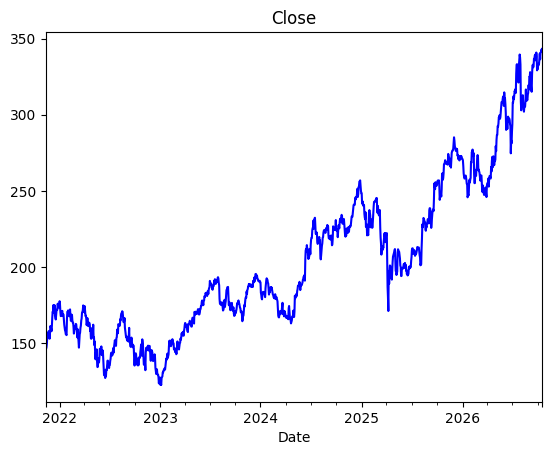

In [89]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1.   Representa la tendencia de las acciones de la empresa con el paso de los años, especificamente entr 2022 y 2026
2.   Su comportamiento es ascendente, es decir, el valor de las acciones ha ido aumentendo con el paso de los años, a pesar de que entre el 2022 y 2023 su comportamiento fue descendente.

2.   Tambien podemos observar que en el año 2023 las acciones tuvieron su pico mas bajo de valor para posteriormente ir en la alza a partir de 2024.

3.  En base a estos dos puntos anteriores podemos deducir que el comportamiento de estas acciones no aumenta de manera constante, debido a las altas y bajas que tienen a lo largo del tiempo.

5.   Actualmente en el año 2026 se muestra el mayor valor de cierre en las acciones, teniendo un aproximado de 340 dolares.



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [90]:
test['y'].values #muestra valores del conjunto test en arreglo

array([342.67962646, 339.24224854, 343.7288208 , 347.95562744,
       347.46600342, 343.64889526, 346.83648682, 343.56893921,
       348.64511108, 344.36834717, 338.06314087, 331.64801025,
       349.24465942, 343.90869141, 342.11004639, 350.42373657,
       348.24539185, 355.35998535, 354.88000488, 356.26998901])

In [91]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 342, Predicción = 343.199
>Esperado-real = 339, Predicción = 342.680
>Esperado-real = 343, Predicción = 339.242
>Esperado-real = 347, Predicción = 343.729
>Esperado-real = 347, Predicción = 347.956
>Esperado-real = 343, Predicción = 347.466
>Esperado-real = 346, Predicción = 343.649
>Esperado-real = 343, Predicción = 346.836
>Esperado-real = 348, Predicción = 343.569
>Esperado-real = 344, Predicción = 348.645
>Esperado-real = 338, Predicción = 344.368
>Esperado-real = 331, Predicción = 338.063
>Esperado-real = 349, Predicción = 331.648
>Esperado-real = 343, Predicción = 349.245
>Esperado-real = 342, Predicción = 343.909
>Esperado-real = 350, Predicción = 342.110
>Esperado-real = 348, Predicción = 350.424
>Esperado-real = 355, Predicción = 348.245
>Esperado-real = 354, Predicción = 355.360
>Esperado-real = 356, Predicción = 354.880

Error-Modelo-Naive: RMSE: 5.825


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**



-----------------------------------------------------------------------------

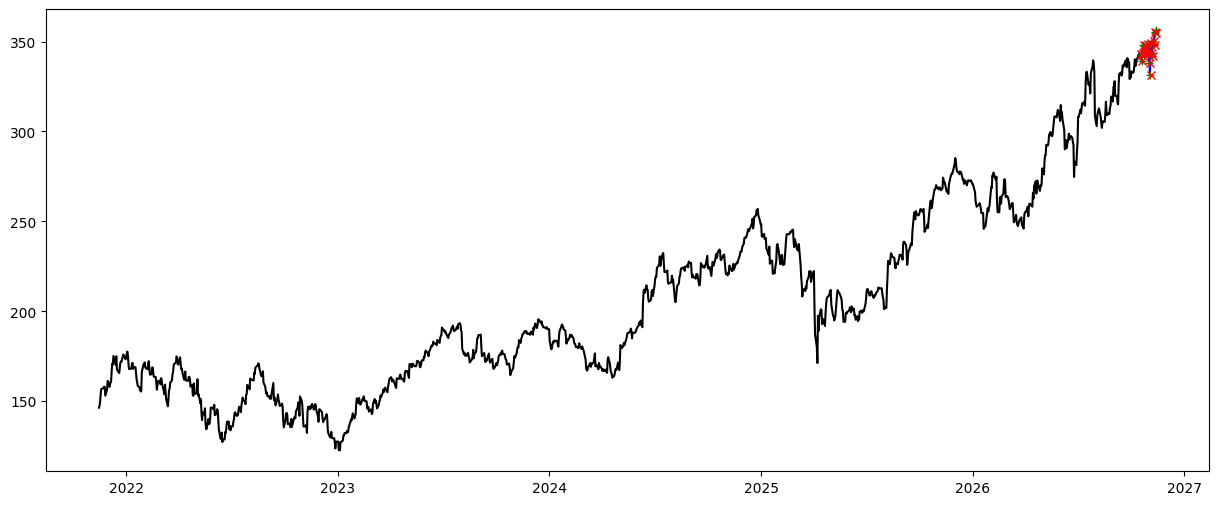

In [92]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------

En la grafica se nos muestra una comparativa entre los valores reales y los predecidos por el modelo, permitiendo observar que tan cerca fueron dichas predicciones contra los valores reales.
Aunque podemos observar un comportamiendo bastante similar entre los valores, si se puede observar una pequeña diferencia entre ellos, por lo que el modelo no puede predecir absolutamente todos los valores a la perfeccion mas sin embargo parece ser que este mismo puede seguir las altas y bajas que pueden tener los precios de las acciones, podemos considerar que el modelo es bueno a la hora de predecir ya que si observamos el error RMSE es de 5.825.



----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

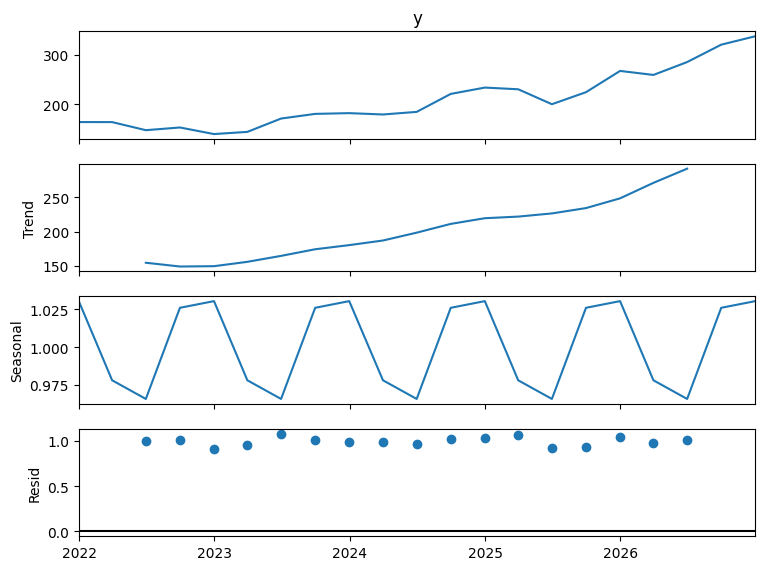

In [93]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**, esta grafica contiene los valores de los datos originales que hemos podido observar en la primera grafica, observando sus valores desde 2022 hasta 2026.

2. **Tendencia (Trend)**, en esta grafica podemos determinar el comportamiendo de los datos a lo largo del tiempo, en este caso podemos observar un comportamiendo ascendente en la mayoria del tiempo, aunque eso no elimina ciertos picos donde el comportamiento es descencente.

3. **Estacional (Seasonal)**, podemos observar que hay una cierta similitud entre las altas y bajas de las acciones, los valores estacionales altos se encuentran aproximadamente en el primer trimestre de cada año, por lo que podemos decir que existe cierta similitud entre los mismos periodos de diferentes años.

4. **Residuos (Resid)**, en esta grafica podemos observar que la mayoria de los valores de cada año estan cercanos a 1, por lo que el valor del residuo suele considerarse como un error normal aceptable por la fluctuabilidad del dia a dia.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

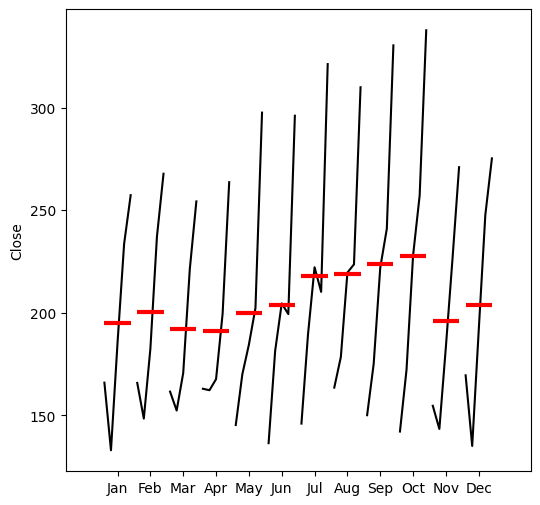

In [94]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

En esta grafica podemos observar que la mayoria de los meses tienen un promedio similar entre si, resaltando que los meses con valores mas altos son octubre y septiembre, siendo estos meses aquellos donde se hacen anuncios o lanzamientos de nuevos productos de la compañia.
Viendo el comportamiendo de los 12 meses podemos ver que hay indicios de una cierta estacionalidad, especialmente en lo observado anteriormente donde de julio a octubre se encuentran los valores mas altos de promedio.


----------------------------------------------------------------------------

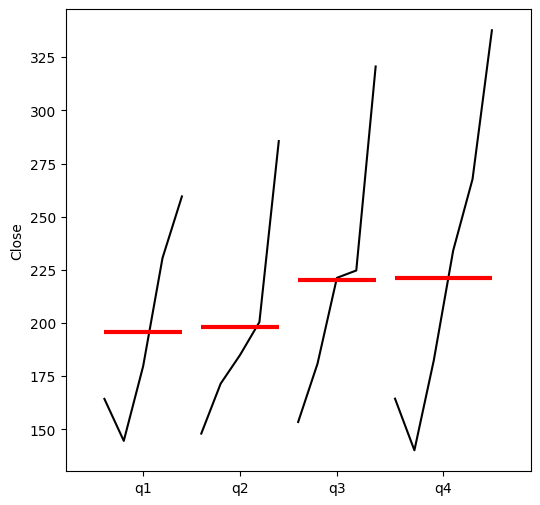

In [95]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------


En esta grafica trimestral podemos observar que los primeros dos trimestres del año presentan promedios similares y relativamente bajos, con un promedio alrededor de los 190 dlls, mientras que el tercer y cuarto trimestre muestran valores más elevados, con su promedio alrededor de los 225 dlls. Esto puede indicar cierta estacionalidad en el comportamiento trimestral de las acciones de Apple como se observo en la grafica anterior. Sin embargo, debido a las variaciones que existen entre los diferentes años, no es posible confirmar que este patrón se repita de manera constante.

----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

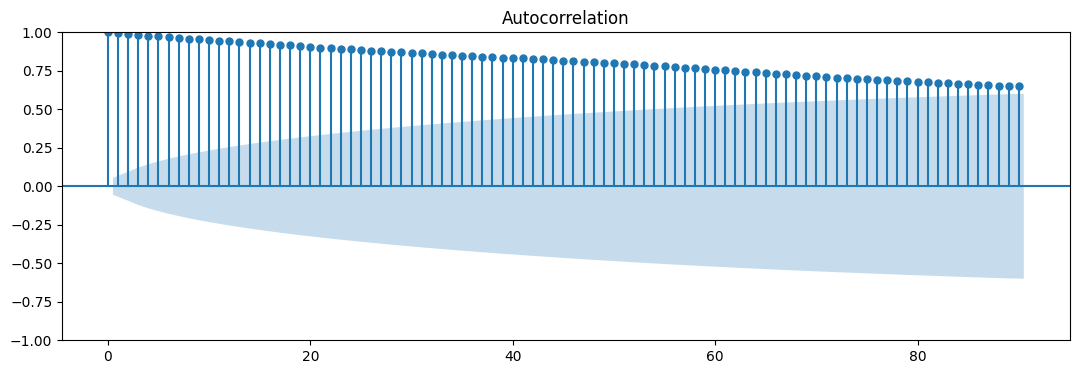

In [96]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

Al principio de la grafica podemos observar que los "lollipops" se encuentran cercanos a 1, por lo que nos muestras una correlacion positiva fuerte con sus valores anteriores. Conforme aumenta el lag va disminuyendo esta correlacion llegando hasta valores cercanos al 0.60 aproximadamente lo que significa que la relacion de los precios se debilita con el paso del tiempo.
Tambien podemos observar que la mayoria de las "lollipops" sobrepasan el sombreado de los intervalos de confianza lo que indica que existe una autocorrelacion positiva.


-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

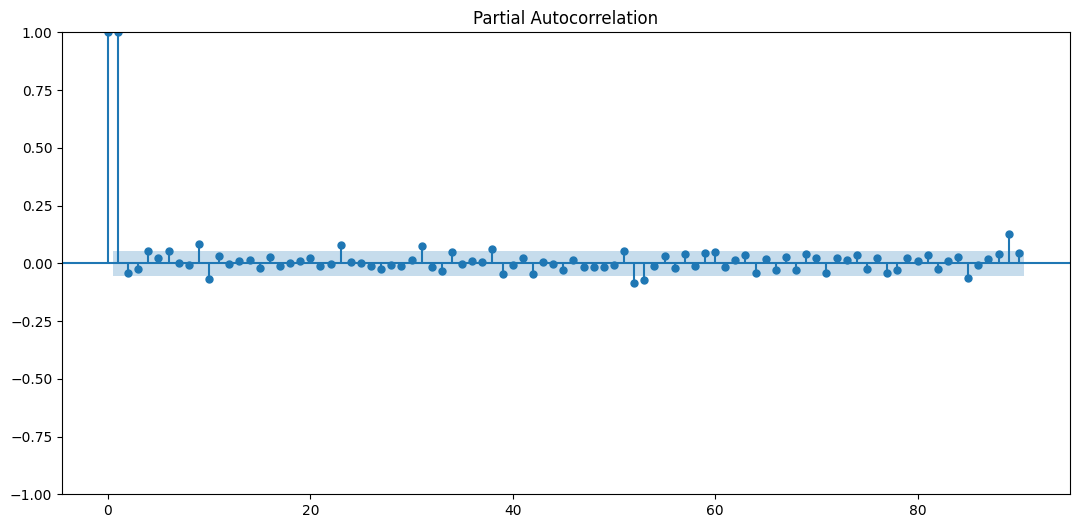

In [97]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------
Podemos observar que los primeros dos "lollipops" tienen una autocorrelacion muy cercana a 1, lo que nos indica que el precio de cierre tiene una correlacion directa con los valores de periodos anteriores, a partir del tercer "lollipop" podemos observar como este valor disminuye considerablemente dando valores mas cercanos al 0.
La mayoria de los  "lollipops" se encuentran dentro del area sombreada del intervalo de confianza, por lo que en este caso no hay autocorrelacion parcial significativa, por lo que no se encuentra una estacionalidad.


----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [98]:
from statsmodels.tsa.arima.model import ARIMA

In [99]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [100]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 342, Predicción = 342.126
>Esperado-real = 339, Predicción = 343.087
>Esperado-real = 343, Predicción = 338.103
>Esperado-real = 347, Predicción = 342.092
>Esperado-real = 347, Predicción = 349.662
>Esperado-real = 343, Predicción = 347.024
>Esperado-real = 346, Predicción = 343.397
>Esperado-real = 343, Predicción = 347.650
>Esperado-real = 348, Predicción = 343.434
>Esperado-real = 344, Predicción = 350.638
>Esperado-real = 338, Predicción = 343.186
>Esperado-real = 331, Predicción = 338.206
>Esperado-real = 349, Predicción = 330.717
>Esperado-real = 343, Predicción = 350.824
>Esperado-real = 342, Predicción = 343.322
>Esperado-real = 350, Predicción = 341.557
>Esperado-real = 348, Predicción = 351.131
>Esperado-real = 355, Predicción = 347.785
>Esperado-real = 354, Predicción = 355.184
>Esperado-real = 356, Predicción = 354.775

Error-Modelo-ARIMA: RMSE: 6.328


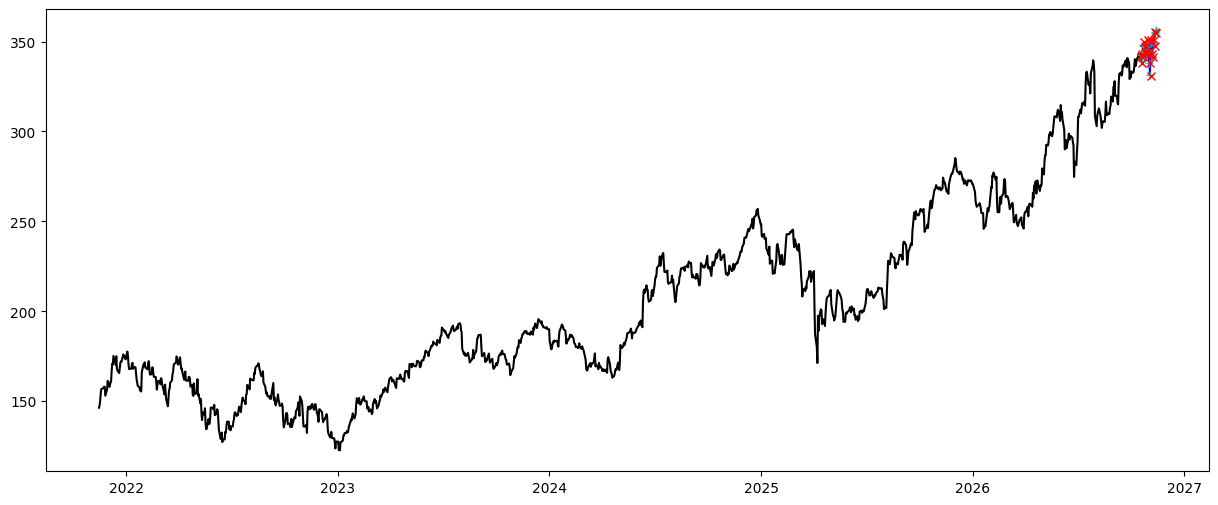

In [101]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------

En base a esta grafica podemos observar que las predicciones realizadas no fueron muy diferentes a los datos reales obtenidos, lo que nos indica que el modelo puede acercarse al comportamiento de los valores reales.
Como podemos observar los valores obtenidos con ARIMA estan entre los 330 y 350 dlls con pequeñas variaciones derivadas de la misma naturaleza del flujo de datos.
Para comprobar la precision del modelo tenemos que comparar los valores predecidos con los reales y utilizar ciertas metricas para evaluar su rendimiento.


----------------------------------------------------------------------------



# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [102]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-15,146.407990
2021-11-16,147.384018
2021-11-17,149.814392
2021-11-18,154.089478
2021-11-19,156.705307


In [103]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-15,146.407990
1,2021-11-16,147.384018
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705307


In [104]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [105]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [106]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 9.545


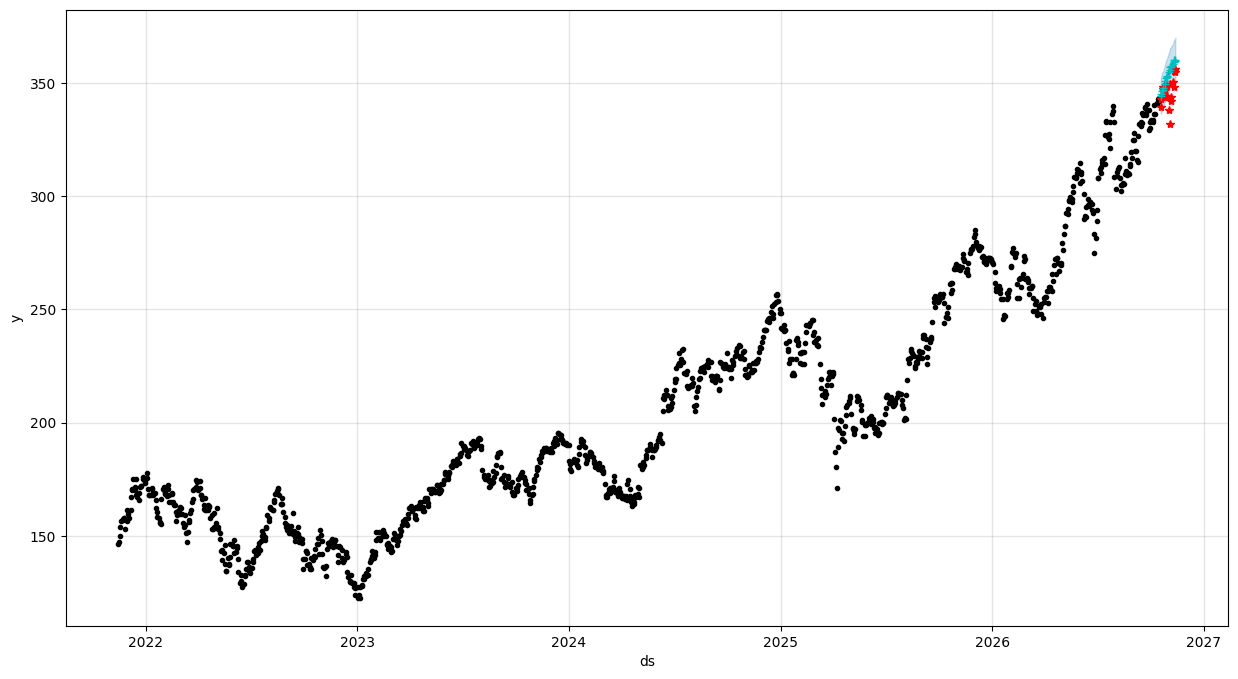

In [107]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos Rojos -> predicciones
Puntos azules -> Datos reales
parte sombreada -> intervalo de confianza de los datos

En la grafica anterior al igual que en las primeras 2 podemos observar el comportamiendo de las accionesd e Apple entre 2021 y 2026, en este caso utilizando el modelo de prediccion Facebook Prophet. Como podemos observar durante las predicciones el modelo logro predecir la tendencia ascendente que tienen los datos, por lo que es capaz de predecir los cambios que van a tener las acciones al pasar el tiempo, ademas de que las predicciones se encuentran relativamente cerda de los valores reales, de igual manera se pueden seguir mejorando los parametros para reducir el RMSE peor aun asi se considera un buen entrenamiento.


-----------------------------------------------------------------------------


# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [108]:
import tensorflow as tf

In [109]:
test.head()

,ds,y
1285,2026-10-19,342.679626
1286,2026-10-20,339.242249
1287,2026-10-21,343.728821
1288,2026-10-22,347.955627
1289,2026-10-23,347.466003


In [110]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.

  # El modelo utiliza 12 observaciones previas para predecir los precios del siguiente bloque.
  # Son 12 días hábiles de la serie, NO 12 meses.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 dias consecutivos

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [111]:
def preparando_datos_1dia(myData, myDate):

    # Ordenar los datos cronológicamente
    datos = myData.sort_values('ds').reset_index(drop=True)

    precios = datos['y'].to_numpy()
    fechas = pd.to_datetime(datos['ds'])

    periodo = 12

    Train_X = []
    Train_Y = []
    Test_X = []
    Test_Y = []

    # Crear ventanas de 12 días para predecir el siguiente
    for i in range(periodo, len(precios)):

        X = precios[i-periodo:i]
        Y = precios[i]

        if fechas.iloc[i] < pd.Timestamp(myDate):
            Train_X.append(X)
            Train_Y.append(Y)
        else:
            Test_X.append(X)
            Test_Y.append(Y)

    # Convertir los datos al formato requerido por LSTM
    Train_X = np.array(Train_X).reshape(-1, periodo, 1)
    Train_Y = np.array(Train_Y).reshape(-1, 1)

    Test_X = np.array(Test_X).reshape(-1, periodo, 1)
    Test_Y = np.array(Test_Y).reshape(-1, 1)

    return Train_X, Train_Y, Test_X, Test_Y

In [112]:
print("Columnas:", df_temp.columns.tolist())
print("Nombre del índice:", df_temp.index.name)

df_temp.head()

Columnas: ['ds', 'y']
Nombre del índice: None


,ds,y
0,2021-11-15,146.407990
1,2021-11-16,147.384018
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705307


In [113]:
# Crear una copia con las fechas como columna
df_lstm = df_temp.reset_index().rename(
    columns={'Date': 'ds'}
)

# Asegurar el orden cronológico
df_lstm['ds'] = pd.to_datetime(df_lstm['ds'])
df_lstm = df_lstm.sort_values('ds').reset_index(drop=True)

# Reservar los últimos 60 registros para prueba
threshold_Date = df_lstm['ds'].iloc[-60]

# Preparar los datos para predecir un día
Train_X, Train_Y, Test_X, Test_Y = preparando_datos_1dia(
    df_lstm, threshold_Date
)

print("Entrenamiento X:", Train_X.shape)
print("Entrenamiento Y:", Train_Y.shape)

print("Prueba X:", Test_X.shape)
print("Prueba Y:", Test_Y.shape)

Entrenamiento X: (1233, 12, 1)
Entrenamiento Y: (1233, 1)
Prueba X: (60, 12, 1)
Prueba Y: (60, 1)


In [182]:
# Continuemos con el DataFrame como en Prophet:

#threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.
threshold_Date = df_lstm['ds'].iloc[-60]

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos_1dia(df_lstm, threshold_Date)

In [115]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.001
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.0001
  else:
    lrate = 0.00005

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Entrenamiento: (1221, 12, 1)
Validación: (12, 12, 1)
Prueba: (60, 12, 1)
Epoch 1/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 12.0331 - root_mean_squared_error: 3.4689 - val_loss: 12.8329 - val_root_mean_squared_error: 3.5823 - learning_rate: 0.0010
Epoch 2/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 12.0299 - root_mean_squared_error: 3.4684 - val_loss: 12.8332 - val_root_mean_squared_error: 3.5824 - learning_rate: 0.0010
Epoch 3/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 12.0310 - root_mean_squared_error: 3.4686 - val_loss: 12.8297 - val_root_mean_squared_error: 3.5819 - learning_rate: 0.0010
Epoch 4/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 12.0295 - root_mean_squared_error: 3.4684 - val_loss: 12.8330 - val_root_mean_squared_error: 3.5823 - learning_rate: 0.0010
Epoch 5/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 12.0277 - root_mean_squared_error: 3.4681 - val_loss: 12.8344 - val_root_mean_squared_error: 3.5825 - learning_rate: 0.0010
Epoch 6/

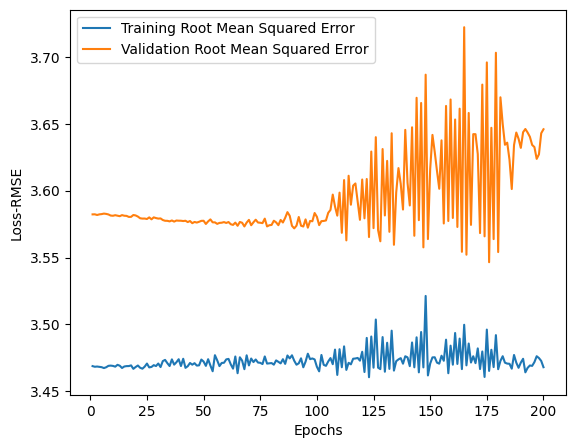

In [116]:
#def myModel():
#  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),

  #model = tf.keras.models.Sequential([tf.keras.layers.LSTM(32, input_shape=(12, 1), activation='tanh', return_sequences=True),
                                      #tf.keras.layers.BatchNormalization(),
                                     # tf.keras.layers.Dropout(0.1),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.1),
                                      #  tf.keras.layers.Dropout(0.2)

                                      #tf.keras.layers.Dense(64, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.Dropout(0.1),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


#                                      tf.keras.layers.Dense(1, activation='linear')
  #                                    ])
 # return model

def myModel():

    entrada = tf.keras.Input(shape=(12, 1))

    # Procesar los 12 precios anteriores
    x = tf.keras.layers.LSTM(
        32,
        activation='tanh',
        return_sequences=False
    )(entrada)

    x = tf.keras.layers.Dropout(0.1)(x)

    x = tf.keras.layers.Dense(
        64,
        activation=tf.nn.leaky_relu
    )(x)

    x = tf.keras.layers.Dropout(0.1)(x)

    # Aprender el cambio respecto al último precio
    cambio = tf.keras.layers.Dense(
        1,
        activation='linear',
        kernel_initializer='zeros',
        bias_initializer='zeros'
    )(x)

    # Obtener el último precio conocido
    ultimo_precio = tf.keras.layers.Lambda(
        lambda z: z[:, -1, :],
        output_shape=(1,)
    )(entrada)

    # Predicción = último precio + cambio aprendido
    salida = tf.keras.layers.Add()([
        ultimo_precio, cambio
    ])

    model = tf.keras.Model(
        inputs=entrada,
        outputs=salida
    )

    return model

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
# Separación de entrenamiento y validación

X_entreno = Train_X[:-12]
Y_entreno = Train_Y[:-12]

Val_X = Train_X[-12:]
Val_Y = Train_Y[-12:]

print("Entrenamiento:", X_entreno.shape)
print("Validación:", Val_X.shape)
print("Prueba:", Test_X.shape)

my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )

H = my_LSTM_model2.fit(X_entreno,
                       Y_entreno,
                       epochs=200,
                       validation_data=(Val_X, Val_Y),
                       callbacks=[callback],
                       shuffle=False
                       )


N = 0  # 50 Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [181]:
# Obtener predicciones utilizando los datos originales
pred_LSTM = my_LSTM_model2.predict(Test_X)

# Tomar las últimas 20 predicciones
pred_LSTM = pred_LSTM.reshape(-1)[-20:]

# Precios reales correspondientes
real_LSTM = Test_Y.reshape(-1)[-20:]

print("Últimas 5 predicciones:")
print(np.round(pred_LSTM[-5:], 2))

print("\nÚltimos 5 precios reales:")
print(np.round(real_LSTM[-5:], 2))

pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Últimas 5 predicciones:
[-20.78 -17.8  -10.88 -19.25 -26.92]

Últimos 5 precios reales:
[1.02 1.01 0.98 0.95 1.03]


(20,)

In [180]:
# Calculamos el error RMSE del modelo LSTM

rmse_lstm_original = np.sqrt(
    mean_squared_error(real_LSTM, pred_LSTM)
)

print('\nError-Modelo-LSTM (Datos Originales): RMSE: %.3f'
      % rmse_lstm_original)


Error-Modelo-LSTM (Datos Originales): RMSE: 15.433


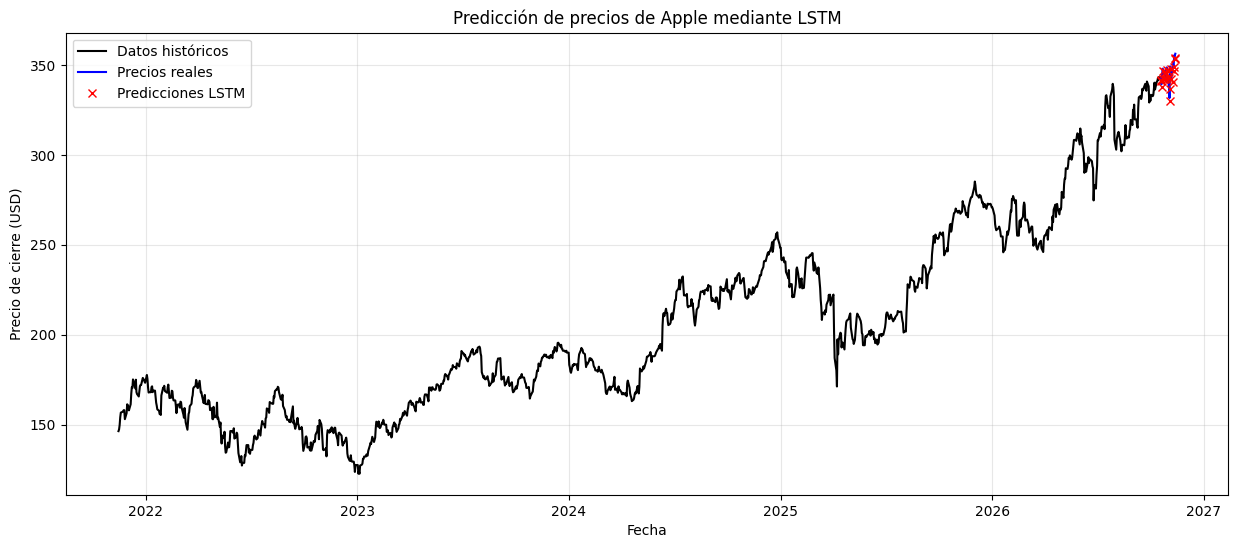

In [120]:
# Gráfica LSTM con datos originales

fechas_LSTM = df_lstm['ds'].iloc[-20:]

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    df_lstm['ds'].iloc[:-20],
    df_lstm['y'].iloc[:-20],
    '-k',
    label='Datos históricos'
)

ax.plot(
    fechas_LSTM,
    real_LSTM,
    '-b',
    label='Precios reales'
)

ax.plot(
    fechas_LSTM,
    pred_LSTM,
    'xr',
    label='Predicciones LSTM'
)

ax.set_title('Predicción de precios de Apple mediante LSTM')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de cierre (USD)')

ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

Para poder mejorar los resultados del modelo LSTM se tuvieron que realizar varios cambios, el primero de ellos fue el probar diferentes parametros/elementos de la
arquitectura ya existente, los cuales fueron:

| Elemento | Modelo original | Modelo modificado |
| :--- | :--- | :--- |
| **Neuronas LSTM** | 20 | 32 |
| **Activación LSTM** | Leaky ReLU | Tanh |
| **return_sequences** | True | False |
| **BatchNormalization** | Activada | Desactivada |
| **Primer Dropout** | 0.3 | 0.1 |
| **Capa Dense** | 64 neuronas | 64 neuronas |
| **Segundo Dropout** | 0.2 | 0.1 |
| **Capa de salida** | Dense(1), linear | Dense(1), linear |
| **Épocas** | 200 | 200 |



---
*Preparacion de los datos*

Empezando por la necesidad de modificar la forma en la que se prepararon los datos. Original,ente la funcion preparando_datos agrupaba los bloques consecutivos de 12 precios para predecir los 12 siguientes, despues de varias evaluaciones se concluyo que no era lo mas optimo, por lo que posteriormente se implemento la funcion preparando_datos_1dia que al recibir los 12 precios de los dias anteriores se encarga de predecir unicamente el precio del siguiente dia. Esto con el fin de pdoer evaluar de manera mas optima el comportamiendo del modelo.

Ademas se modifico la fecha de separacion de los datos que inicialmente estaba definida como *threshold_Date = '2024-09-11'*, por lo que el entrenamiento no incluia los precios mas recientes de nuestra serie, esto generaba conflicto con el modelo porque esta parte era la que nos proporcionaba un precio maximo de alrededor de $232, mientras que las predicciones a las que tenia que llegar rondaban los $350, por ello se realizo el cambio en el codigo para que la fecha de separacion reservara los ultimos 60 registros como conjunto de prueba con el fin de incorporar informacion mas reciente al entrenamiento.

---
*Test y train del modelo*


Pasando para el lado del entrenamiento, en el caso del cambio del numero de neuronas se incrementaron para poder aumentar la capacidad del modelo para identificar relaciones entre los precios historicos ya que a lo largo de diferentes pruebas un problema que se identifico fue el que las predicciones no contemplaban el aumento de precios de las acciones.

Tambien se cambio la funcion de activación de Leaky ReLU a Tanh, ya que es una función utilizada comunmente en este tipo de redes.

Despues se redujeron los valores de Dropout de 0.2 a 0.1, para permitir que el modelo aprovechara más unidades durante el entrenamiento. También se hicieron pruebas con BatchNormalization, pero finalmente se decidio mantenerla desactivada.

Al principio, aunque el error de entrenamiento disminuía, las predicciones seguían siendo muy diferentes de los precios reales. Por eso revisamos la preparación de los datos y encontramos que el modelo estaba entrenándose con precios históricos considerablemente menores que los que debía predecir.

Por lo que despues de una investigacion se incorporo una conexion residual a la arquitectura con el fin de que se utilizara el ultimo precio conocido como referencia y en base a ese se hiciera un ajuste sobre dicho valor, que para poder obtenerlo se incorporo Lambda y con una capa Add se suma ese precio al cambio ya estimado por la red neuronal.

Por esto mismo, la capa Dense que es la encargada de realizar este calculo se inicializo con pesos y sesgos en cero para que inicialmente el modelo utilizara el ultimo precio como referencia y para que despues pueda aprender correciones durante el entrenamiento.


# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**
**Grafica 1:**
> En la grafica analizamos el comportamiendo del error RMSE en las 200 epocas que asignamos de entrenamiento. Se observa que el error de entrenamiento se mantiene relativamente estable, alrededor de 3.47, mientras que el de validacion comienza aproximadamente en 3.58. A partir de la epoca 100 la curva de validacion presenta fluctuaciones mas pronunciadas, llegando a superar el valor de 3.80. Esto indica cierta inestabilidad durante el entrenamiento, ya que el modelo no consigue disminuir significativamente su error conforme avanzan las epocas. Sin embargo, gracias a la conexión residual, logra mantener errores relativamente bajos desde el inicio al utilizar el último precio conocido como referencia.

**Grafica 2:**
> Con base a lo comentado anteriormente y a lo que se aprecia en la grafica podemos deducir que el modelo tuvo predicciones cercanas a los valores reales lo que podemos relacionar con las modificaciones realizadas sobretodo de la conexion residual, sin embargo se puede observar que son un poco inferiores a los valores reales, lo que podemos deducir como una tendencia del modelo a subestimar los precios de las acciones dando como resultado un RMSE de 6.375 dolares, mostrando una mejora considerable comparandolo con versiones anteriores.

En general los resultados nos muestran que la red logro aprender patrones de la serie de tiempo establecida y logra generar predicciones mas cercanas a los valores reales, aunque aun existen mejoras que se pueden realizar para una mejor precision.



----------------------------------------------------------------------------


----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 5.825 |
| 2 | Modelo ARIMA | 6.223 |
| 3 | Modelo Facebook-Meta-Prophet | 8.597|
| 4 | Long Short Term Memory (LSTM) | 6.375 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

Al comparar los valores de RMSE obtenidos en cada uno de los 4 modelos analizados anteriormente podemos observar que el Modelo Ingenuo presento el menor error siendo este 5.825 dolares, siguiendole ARIMA con 6.223, despues LSTM con 6.375 y por ultimo Facebook Prophet con 8.597 dolares. Con esto podemos observar que el modelo ingenuo a pesar de ser el mas sencillo fue el que obtuvo las predicciones mas precisas, por lo que podemos concluir que el modelo mas complejo no necesariamente sera el que generemejores predicciones, ejemplo que se vio sobre todo en el desarrollo/modificaciones del modelo LSTM siendo que al terminar no dio el mejor resultado. Aunque hay que tener en cuenta que esto solo es una estrategia realmente efectiva para realizar predicciones a corto plazo, ya que otros modelos como ARIMA y LSTM logran identificar relaciones a lo largo de las series de tiempo aunque pueden presentar limitaciones al anticipar las variaciones de los precios o cualquier contexto que se pueda presentar.

---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [162]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [163]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-15,146.407990,0.107381
1,2021-11-16,147.384018,0.111808
2,2021-11-17,149.814392,0.122832
3,2021-11-18,154.089478,0.142223
4,2021-11-19,156.705307,0.154088


In [164]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [165]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-15,0.107381
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


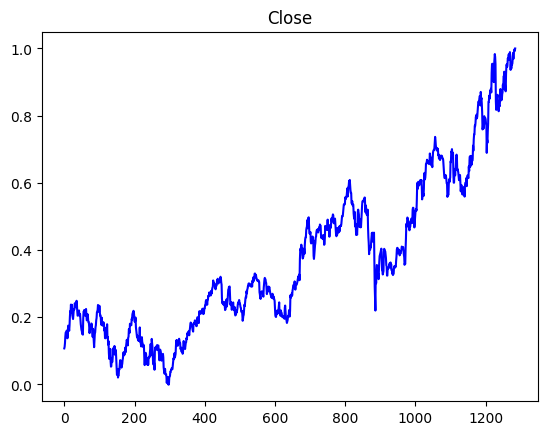

In [166]:
train_escalado['y_escalado'].plot(title='Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------

En esta grafica al igual que en la primera seccion de datos originales podemos observar el comportamiendo de los precios de las acciones de Apple pero en este caso despues de haber aplicado el escalamiento de los datos. La tendencia se mantiene ascendente y al compararla con la grafica de detos originales, observamos que ambas graficas presentan el mismo comportamiento, conservando las altas y bajas que tiene la serie a lo largo del tiempo. La diferencia principal que podemos observar es uqe hora los valores de entrenamiento se encuentran en un rango entre 0 y 1 en lugar de representar los datos en su formato original (dolares), siendo este el cambio mas significativo.


-----------------------------------------------------------------------------

In [167]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.9976432 , 0.9820517 , 1.00240221, 1.02157445, 1.01935358,
       1.00203967, 1.01649818, 1.001677  , 1.02470186, 1.00530301,
       0.97670342, 0.94760522, 1.02742133, 1.00321808, 0.99505966,
       1.03276948, 1.02288879, 1.05515966, 1.05298253, 1.05928732])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [129]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.998, Predicción = 1.000
>Esperado-real = 0.982, Predicción = 0.998
>Esperado-real = 1.002, Predicción = 0.982
>Esperado-real = 1.022, Predicción = 1.002
>Esperado-real = 1.019, Predicción = 1.022
>Esperado-real = 1.002, Predicción = 1.019
>Esperado-real = 1.016, Predicción = 1.002
>Esperado-real = 1.002, Predicción = 1.016
>Esperado-real = 1.025, Predicción = 1.002
>Esperado-real = 1.005, Predicción = 1.025
>Esperado-real = 0.977, Predicción = 1.005
>Esperado-real = 0.948, Predicción = 0.977
>Esperado-real = 1.027, Predicción = 0.948
>Esperado-real = 1.003, Predicción = 1.027
>Esperado-real = 0.995, Predicción = 1.003
>Esperado-real = 1.033, Predicción = 0.995
>Esperado-real = 1.023, Predicción = 1.033
>Esperado-real = 1.055, Predicción = 1.023
>Esperado-real = 1.053, Predicción = 1.055
>Esperado-real = 1.059, Predicción = 1.053

Error-Modelo-Naive con datos escalados: RMSE: 0.026


In [174]:
# Regresar las predicciones a dólares
pred_dolares = scaler.inverse_transform(np.array(predictions).reshape(-1, 1))

# Calcular RMSE en dólares
rmse = np.sqrt(mean_squared_error(test['y'], pred_dolares))

print('RMSE Naive en dolares: %.3f' % rmse)

RMSE Naive en dolares: 5.825


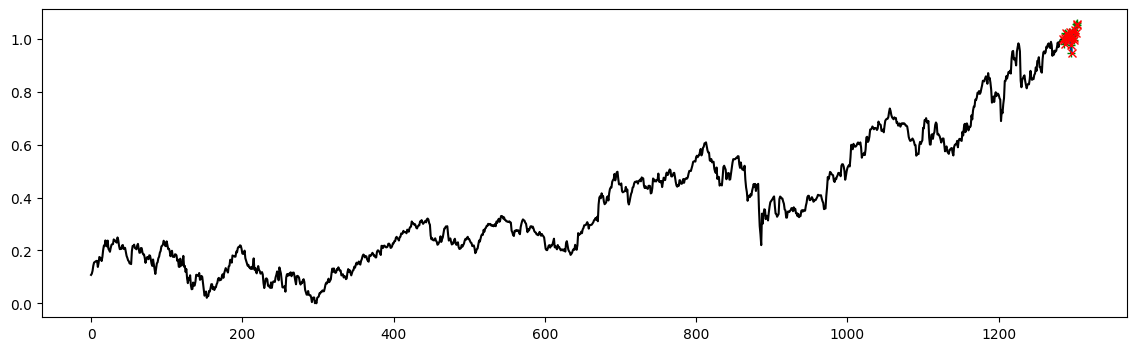

In [130]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

----------------------------------------------------------------------------

En la grafica podemos observar que las predicciones del modelo ingenuo escalado se encuentran bastante cerca de los ultimos valores reales de la serie, manteniendo un comportamiento bastante similar al obtenido con los datos originales. La diferencia mas grande al igual que en la grafica anterior es que los valores estan representados en una escala diretente. Por lo que podemos determinar que se obtuvo un rendimiento equivalente a los datos originales al convertir las predicciones nuevamente a dolares donde se obtuvo un RMSE de 5.825.


----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [131]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-15,0.107381
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [132]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1285,2026-10-19,0.997643
1286,2026-10-20,0.982052
1287,2026-10-21,1.002402
1288,2026-10-22,1.021574
1289,2026-10-23,1.019354


In [133]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [134]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [135]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-15,0.107381
2021-11-16,0.111808
2021-11-17,0.122832
2021-11-18,0.142223
2021-11-19,0.154088


In [136]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-19,0.997643
2026-10-20,0.982052
2026-10-21,1.002402
2026-10-22,1.021574
2026-10-23,1.019354


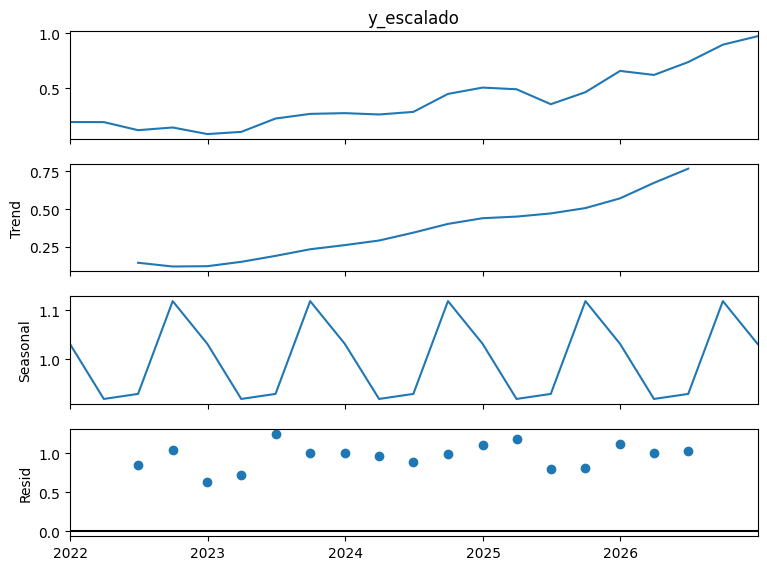

In [137]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

------------------------------------------------------------------------
#<FONT COLOR=WHITE>


1.   **Grafica original**: Se observa que los datos conservan el mismo comportamiendo que en la grafica anterior, mostrando una tendencia general ascendente, de igual manera la mayor diferencia es que ahora los datos se encuentran escalados entre 0 y 1 para el conjunto de entrenamiento.
2.   **Tendencia**: Al igual que con los datos originales y como se menciono anteriormente se obserca una tendencia ascendente sobretodo a partor de 2023, por lo que el escalamiento conservo la direccion general de los precios de las acciones.
3. **Estacionalidad**: Se sigue observando un patron que se repite aproximadamente cada cuatro trimestres muy similar al de la grafica original. Sin embargo, las altas y bajas son mas pronunciadas, lo que podemos asumir ocmo una relacion directa con el escalamiento y el tipo de descomposicion multiplicativa utilizada sin que exista una mayor estacionalidad.
4. **Residual**: A diferencia de los datos originales donde los datos se encontraban muy cercanos a 1, ahora presentan una mayor dispersion, aproximadamente entre 0.6 y 1.3, lo que nos muestra que el escalamiento tambien modifica la magnitud de los residuos.



--------------------------------------------------------------------------

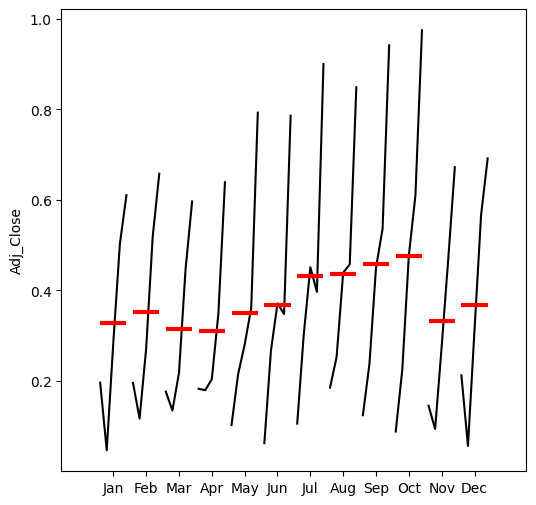

In [138]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

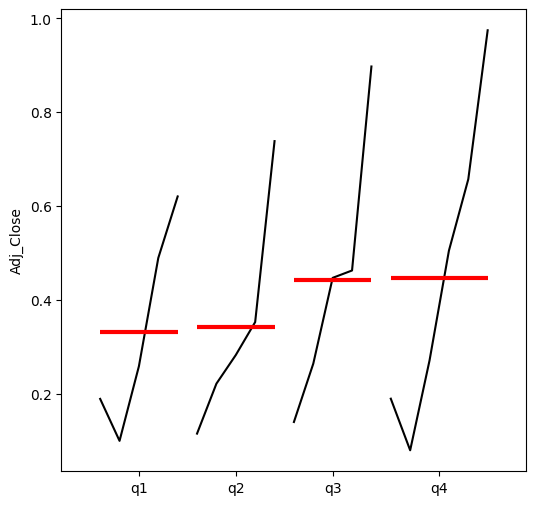

In [139]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

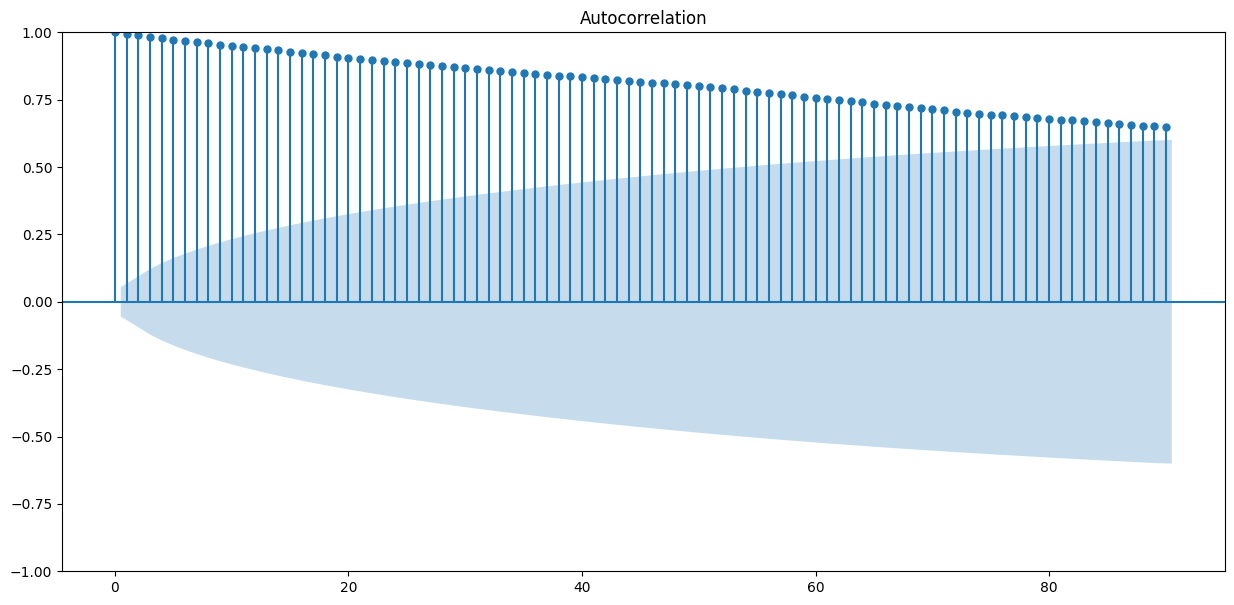

In [140]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


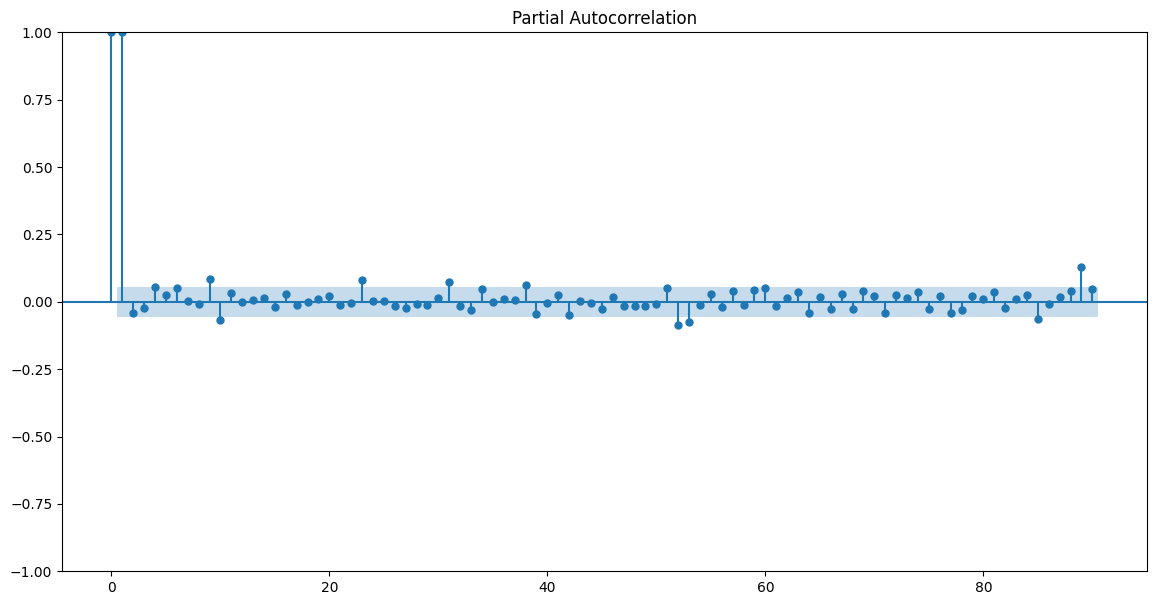

In [141]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [142]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.998, Predicción = 0.983
>Esperado-real = 0.982, Predicción = 1.008
>Esperado-real = 1.002, Predicción = 0.977
>Esperado-real = 1.022, Predicción = 0.999
>Esperado-real = 1.019, Predicción = 1.034
>Esperado-real = 1.002, Predicción = 1.029
>Esperado-real = 1.016, Predicción = 0.981
>Esperado-real = 1.002, Predicción = 1.033
>Esperado-real = 1.025, Predicción = 1.001
>Esperado-real = 1.005, Predicción = 1.026
>Esperado-real = 0.977, Predicción = 1.004
>Esperado-real = 0.948, Predicción = 0.978
>Esperado-real = 1.027, Predicción = 0.949
>Esperado-real = 1.003, Predicción = 1.013
>Esperado-real = 0.995, Predicción = 1.028
>Esperado-real = 1.033, Predicción = 1.009
>Esperado-real = 1.023, Predicción = 1.036
>Esperado-real = 1.055, Predicción = 1.005
>Esperado-real = 1.053, Predicción = 1.066
>Esperado-real = 1.059, Predicción = 1.040

Error-Modelo-ARIMA: RMSE: 0.031


In [176]:
# Regresar las predicciones a dólares
pred_dolares = scaler.inverse_transform(np.array(predictions_escalado).reshape(-1, 1))

# Calcular RMSE en dólares
rmse = np.sqrt(mean_squared_error(test['y'], pred_dolares))

print('RMSE ARIMA en dólares: %.3f' % rmse)

RMSE ARIMA en dólares: 6.805


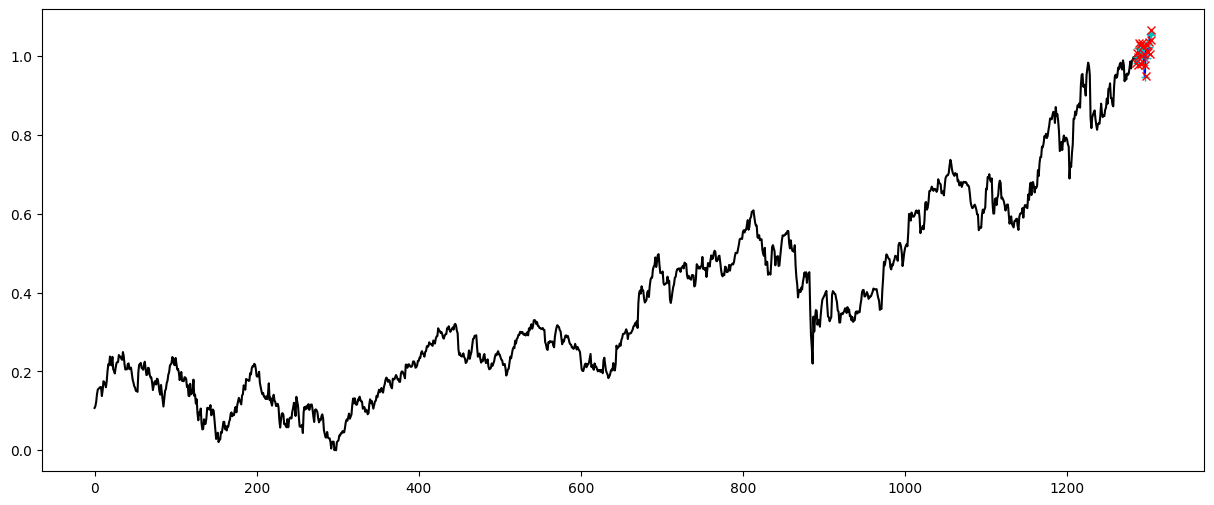

In [143]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------

En esta grafica podemos observar que al igual que la grafica con datos originales, las predicciones se mantienen relativamente cerca a los valores reales, aunque presentan algunas diferencias en las altas y bajas de los precios.
Al hacer la comparativa con la grafica obtenida anteriormente de igual manera podemos observar la misma tendencia ascendente que tienen las acciones, el punto mas diferenciador siguen siendo que estan en una escala normalizada y no directamente en dorales. En cuanto al RMSE, con los datos escalados se obtuvo un valor de 0.031 que una vez que transformamos de vuelta a dolares tenemos 6.805 dolares, que comparansolo con el modelo original que nos dio 6.223 dolares podemos observar que si bien si se obtuvo un valor un tanto diferente no representa una gran diferencia considerando que se tuvo casi el mismo comportamiendo en ambos modelos.

-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [144]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-15,146.407990
1,2021-11-16,147.384018
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705307


In [145]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-15,146.407990
1,2021-11-16,147.384018
2,2021-11-17,149.814392
3,2021-11-18,154.089478
4,2021-11-19,156.705307


In [146]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [147]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [148]:
train_escalado.head()

,ds,y
0,2021-11-15,0.107381
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [149]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [150]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.033


In [183]:
# Regresar las predicciones a dólares
pred_dolares = scaler.inverse_transform(np.array(pred_FP_escalado).reshape(-1, 1))

# Calcular RMSE en dólares
rmse = np.sqrt(mean_squared_error(test['y'], pred_dolares.ravel()))

print('RMSE Prophet en dólares: %.3f' % rmse)

RMSE Prophet en dólares: 7.327


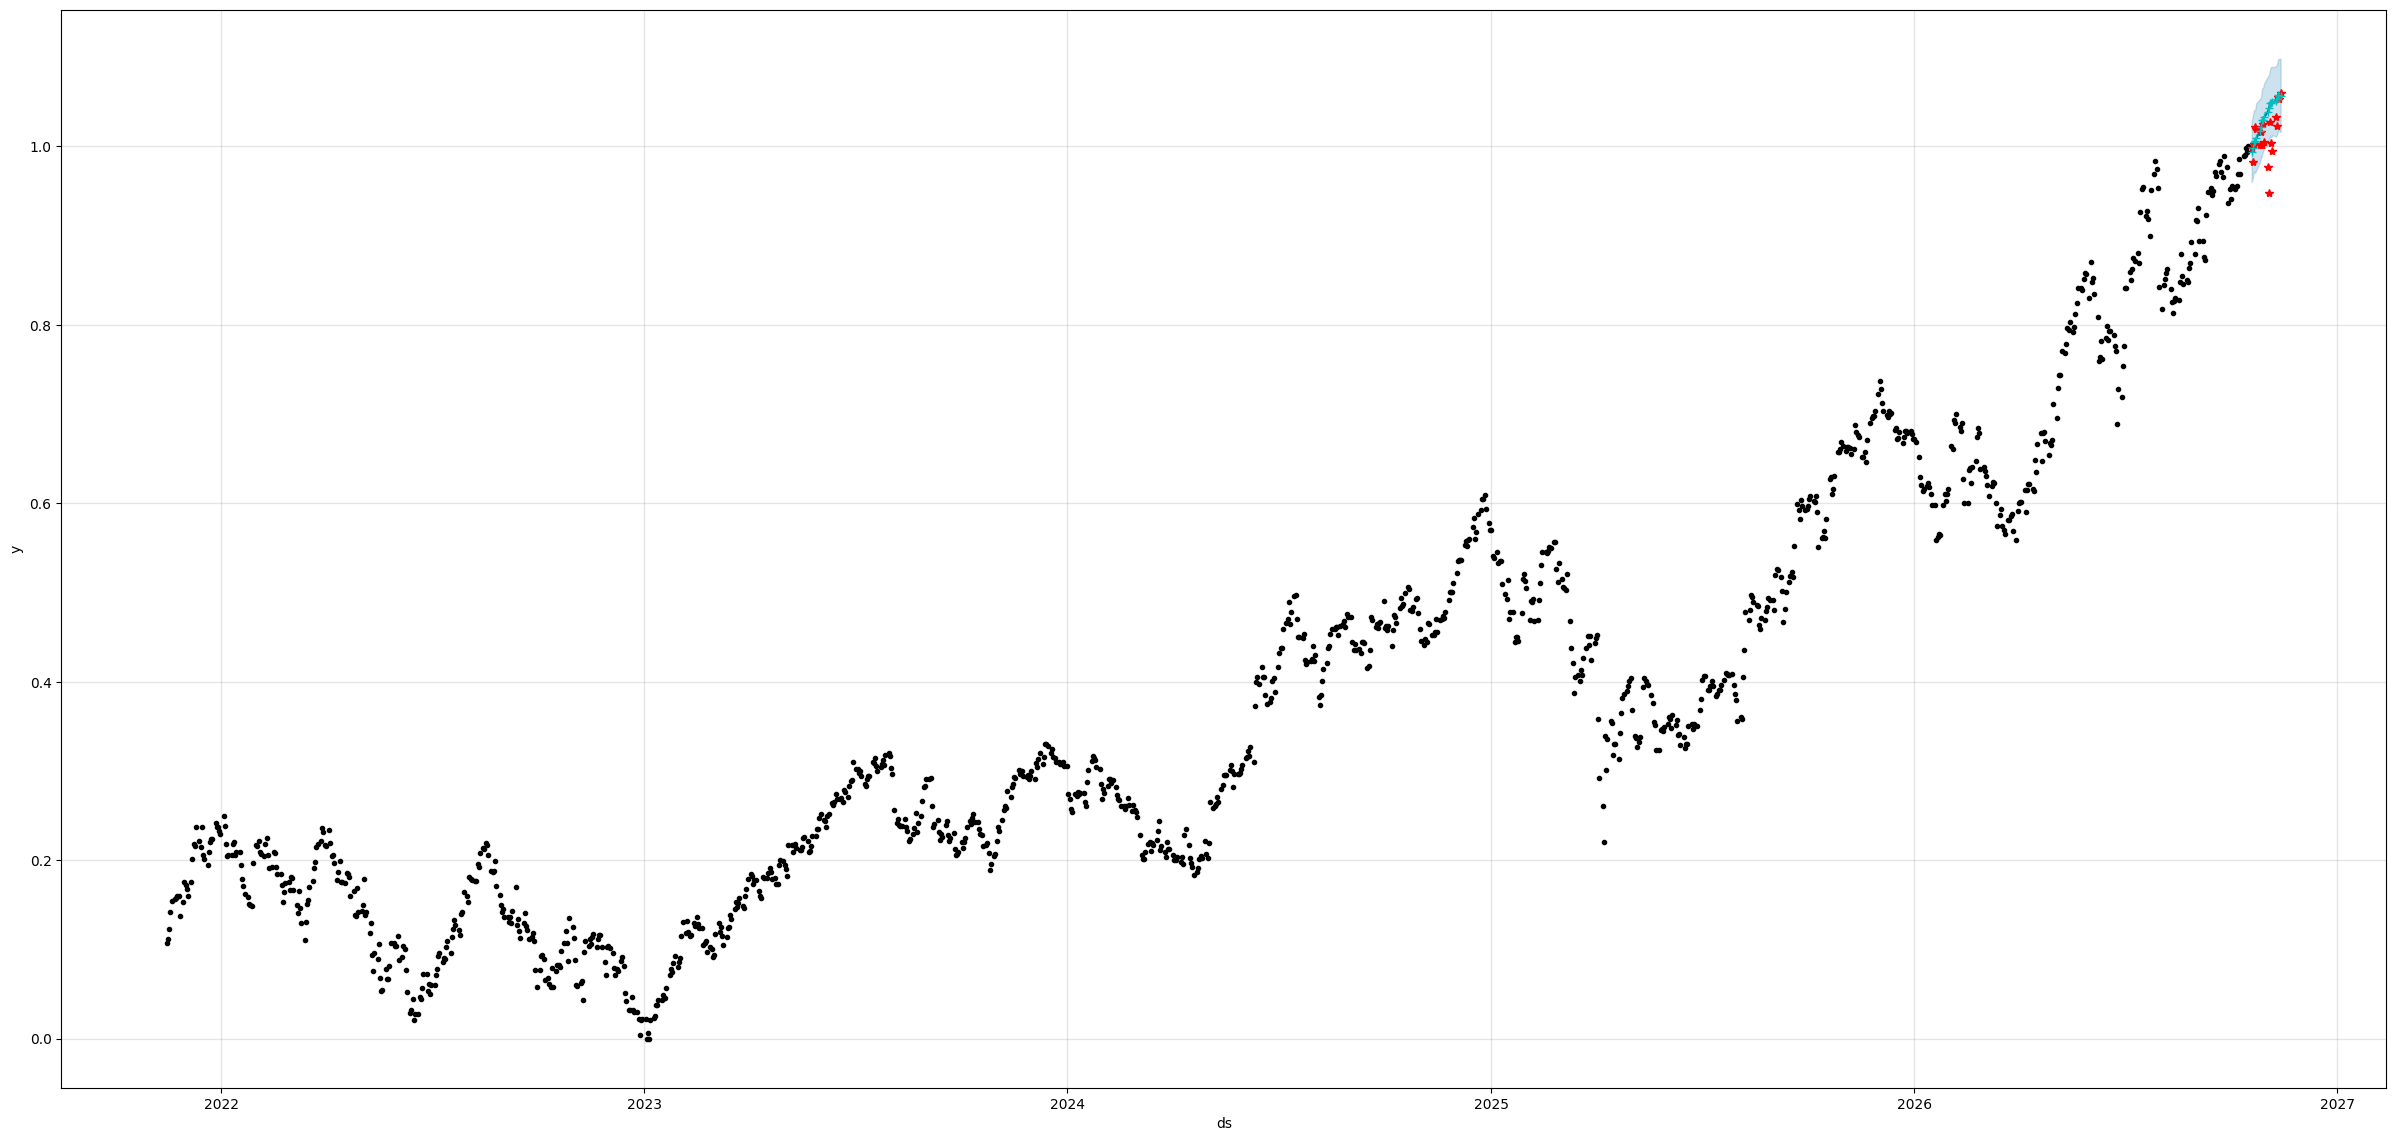

In [151]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

------------------------------------------------------------------------

En esta grafica podemos observar que las predicciones de modelo Prophet se encuentran de nueva cuenta cercanos a los valores reales, al compararla con la grafica de datos originales podemos observar que ambas mantienen un comportamiento similar siguiendo la tendencia de las acciones de Apple, aunque sigue siendo el modelo que hasta el momento presenta el mayor valor de RMSE, que con los datos escalados se obtuvo un valor de 0.033 que trasladandolo a dolares seria alrededor de 7.327 dlls, mostrandose un mejor comportamiento del modelo que el de datos originales donde obtuvimos 8.597 dolares. Por lo que en general este modelo presento un mejor comportamiento comparandolo con los datos originales.


-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [226]:
df_temp_escalado.head()

,ds,y
0,2021-11-15,0.107381
1,2021-11-16,0.111808
2,2021-11-17,0.122832
3,2021-11-18,0.142223
4,2021-11-19,0.154088


In [229]:
df_lstm_escalado = df_lstm.copy()

scaler_lstm = MinMaxScaler(feature_range=(0, 1)) #Se crea el escalador para tener los valores entre 0 y 1

scaler_lstm.fit(df_lstm_escalado[['y']].iloc[:-72]) # Excluimos 60 registros de prueba y 12 de validacion

df_lstm_escalado['y'] = scaler_lstm.transform(df_lstm_escalado[['y']]).ravel() # Se aplica el escalamiento a los precios

df_lstm_escalado.head()

,index,ds,y
0,0,2021-11-15,0.109198
1,1,2021-11-16,0.113701
2,2,2021-11-17,0.124911
3,3,2021-11-18,0.144631
4,4,2021-11-19,0.156696


*NOTA*: Volvimos a aplicar el escalamiento debido a que esta version esta ajustada especificamente para el modelo LSTM

In [230]:
# Continuemos con el DataFrame como en Prophet:

#threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.
threshold_Date_escalado = df_lstm_escalado['ds'].iloc[-60] #Reservamos los ultimos 60 registros para pruebas

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

#Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)
Train_X_escalado, Train_Y_escalado, Test_X_escalado, Test_Y_escalado = preparando_datos_1dia(df_lstm_escalado, threshold_Date_escalado)

#Imprimimos para corroborar la distribucion de los datos
print("Entrenamiento X:", Train_X_escalado.shape)
print("Entrenamiento Y:", Train_Y_escalado.shape)
print("Prueba X:", Test_X_escalado.shape)
print("Prueba Y:", Test_Y_escalado.shape)

Entrenamiento X: (1233, 12, 1)
Entrenamiento Y: (1233, 1)
Prueba X: (60, 12, 1)
Prueba Y: (60, 1)


In [231]:
# Separamos los últimos 12 registros de entrenamiento para validación
X_entreno_escalado = Train_X_escalado[:-12]
Y_entreno_escalado = Train_Y_escalado[:-12]

# Los últimos 12 registros se utilizan para validar el modelo
Val_X_escalado = Train_X_escalado[-12:]
Val_Y_escalado = Train_Y_escalado[-12:]

# Comprobamos las dimensiones de los conjuntos
print("Entrenamiento:", X_entreno_escalado.shape)
print("Validación:", Val_X_escalado.shape)
print("Prueba:", Test_X_escalado.shape)

Entrenamiento: (1221, 12, 1)
Validación: (12, 12, 1)
Prueba: (60, 12, 1)


In [210]:
''''def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

_IncompleteInputError: incomplete input (447310548.py, line 1)

In [235]:
def myModel():
    # Muchos de los parametros del modelo anterior se conservan de igual manera, solo que distribuidos en variables para su uso posterior.
    # se define la entrada donde se establecen 12 precios anteriores y 1 caracteristica por precio
    entrada = tf.keras.Input(shape=(12, 1))

    # Capa LSTM de 32 neuronas
    x = tf.keras.layers.LSTM(32, activation='tanh', return_sequences=False)(entrada)

    x = tf.keras.layers.Dropout(0.1)(x) # Desactivamos aleatoriamente el 10% de entrenamiento
    x = tf.keras.layers.Dense(64, activation=tf.nn.leaky_relu)(x) # Capa de 64 neuronas
    x = tf.keras.layers.Dropout(0.1)(x) # Reducimos el riego de sobreajuste

    # Se calcula el cambio que el modelo tiene respecto al ultimo precio,
    # al igual que el modelo original inicializamos en cero para tomar el último precio como referencia
    cambio = tf.keras.layers.Dense(1, activation='linear')(x)

    # Al igual que en el modelo original usamos lambda para recuperar el ultimo precio de los 12 valores de entrada
    ultimo_precio = tf.keras.layers.Lambda(lambda z: z[:, -1, :], output_shape=(1,))(entrada)

    salida = tf.keras.layers.Add()([ultimo_precio, cambio])
    # Sumamos el ultimo precio y el cambio aprendido para obtener la prediccion de la misma manera que lo hicimos en el primer modelo
    model = tf.keras.Model(inputs=entrada, outputs=salida)

    return model

In [236]:
def scheduler(epoch):
    if epoch <= 100:
        lrate = 0.001
    elif epoch <= 180:
        lrate = 0.0005
    elif epoch <= 190:
        lrate = 0.0001
    else:
        lrate = 0.00005
    return lrate

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 4.4085e-04 - root_mean_squared_error: 0.0210 - val_loss: 3.7092e-04 - val_root_mean_squared_error: 0.0193 - learning_rate: 0.0010
Epoch 2/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.3783e-04 - root_mean_squared_error: 0.0184 - val_loss: 3.0424e-04 - val_root_mean_squared_error: 0.0174 - learning_rate: 0.0010
Epoch 3/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.8291e-04 - root_mean_squared_error: 0.0196 - val_loss: 2.8294e-04 - val_root_mean_squared_error: 0.0168 - learning_rate: 0.0010
Epoch 4/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.0171e-04 - root_mean_squared_error: 0.0174 - val_loss: 2.6515e-04 - val_root_mean_squared_error: 0.0163 - learning_rate: 0.0010
Epoch 5/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.7232e-04 - root_mean_squared_error: 0.0165 - val_loss: 2.7523e-04 - val_root_mean_squared_error: 0.0166 - learning_rate: 0.0010
Epoch 6/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - l

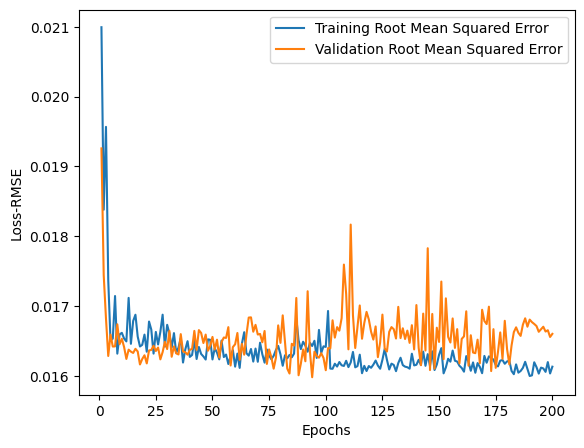

In [240]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(X_entreno_escalado,
                       Y_entreno_escalado,
                       epochs=200,
                       validation_data=(Val_X_escalado, Val_Y_escalado),
                       callbacks=[callback],
                       shuffle=False)



N = 0  # Mostramos todas las épocas para observar el entrenamiento completo

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

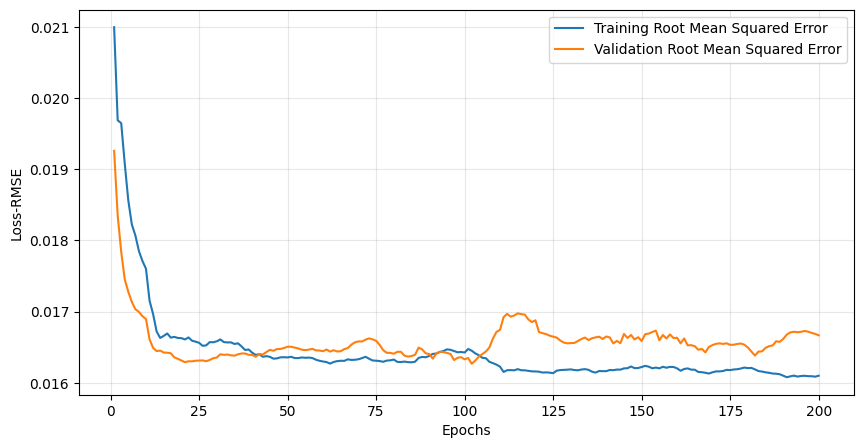

In [242]:
N = 0
epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots(figsize=(10, 5))

# RMSE de entrenamiento suavizado
ax2.plot(epochs,
         pd.Series(H.history["root_mean_squared_error"])
         .rolling(window=10, min_periods=1).mean()[N:],
         label="Training Root Mean Squared Error")

# RMSE de validación suavizado
ax2.plot(epochs,
         pd.Series(H.history["val_root_mean_squared_error"])
         .rolling(window=10, min_periods=1).mean()[N:],
         label="Validation Root Mean Squared Error")

ax2.set(xlabel="Epochs", ylabel="Loss-RMSE")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.show()


In [243]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step


(60,)

In [244]:
# Predecimos los últimos 20 precios y los regresamos a dólares
pred_LSTM_escalado = scaler_lstm.inverse_transform(
    my_LSTM_model2.predict(Test_X_escalado[-20:], verbose=0)
).ravel()

# Regresamos los precios reales a dólares
real_LSTM_escalado = scaler_lstm.inverse_transform(
    Test_Y_escalado[-20:]
).ravel()

# Calculamos el error en dólares
rmse_lstm_escalado = np.sqrt(
    mean_squared_error(real_LSTM_escalado, pred_LSTM_escalado)
)

print("RMSE LSTM escalada en dólares: %.3f" % rmse_lstm_escalado)

RMSE LSTM escalada en dólares: 8.351


In [246]:
# Calculamos el error RMSE con datos escalados:

#pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

#pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
#rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

#print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

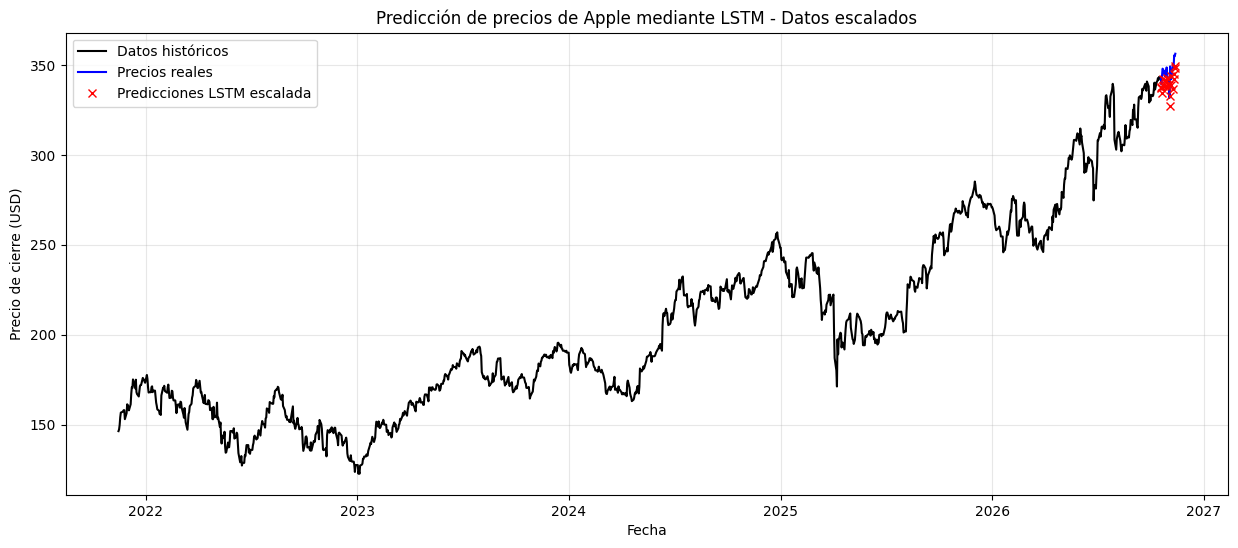

In [248]:

# Graficamos los resultados de la LSTM escalada en dólares

# Fechas correspondientes a los últimos 20 registros
fechas_LSTM_escalado = df_lstm['ds'].iloc[-20:]

fig, ax = plt.subplots(figsize=(15, 6))

# Datos históricos originales
ax.plot(df_lstm['ds'].iloc[:-20], df_lstm['y'].iloc[:-20],
        '-k', label='Datos históricos')

# Precios reales de los últimos 20 días
ax.plot(fechas_LSTM_escalado, real_LSTM_escalado,
        '-b', label='Precios reales')

# Predicciones de la LSTM convertidas a dólares
ax.plot(fechas_LSTM_escalado, pred_LSTM_escalado,
        'xr', label='Predicciones LSTM escalada')

# Configuración de la gráfica
ax.set_title('Predicción de precios de Apple mediante LSTM - Datos escalados')
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio de cierre (USD)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()


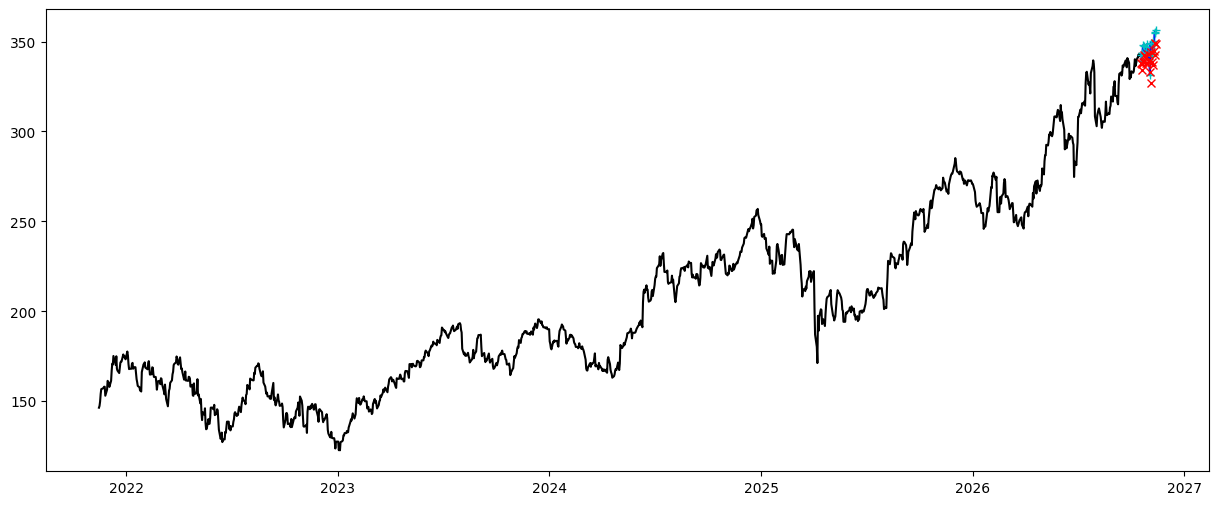

In [250]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df_lstm['ds'].iloc[:-20], df_lstm['y'].iloc[:-20], '-k')
ax.plot(df_lstm['ds'].iloc[-20:], df_lstm['y'].iloc[-20:], '-b')
ax.plot(df_lstm['ds'].iloc[-20:], df_lstm['y'].iloc[-20:], '+c')
ax.plot(df_lstm['ds'].iloc[-20:], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------

**Grafica 1:**
>En la primer agrafica podemos analizar el comportamiendo del RMSE durante las 200 epocas del entrenamiento. Se observa que el error disminuye considerablemente durante las primeras epocas y posteriormente se comienza a estabilizar alrededor de 0.015. SIn embargo, la curva de validacion presenta diferentes picos al igual que en los datos originales, lo que nos da a entender que el modelo todavia tiene ciertas fluctuaciones en su rendimiento, aunque estos errores no se pueden comparar directamente porque se encuentran en diferentes escalas.

**Grafica 2:**
>En esta segunda grafica se utilizo una media movil de 10 epocas para observar con mayor claridad el comportamiendo general del error, es importante mencionar que este procedimiento de suavizar las curvas unicamente suaviza la representacion grafica y no modifica el entrenamiento ni los resultados del modelo, simplemente sirve de ayuda visual para la interpretacion.

**Grafica 3:**
>En la ultima grafica podemos ver que las predicciones obtenidas con LSTM se encunetran relativamente cercanas a los precios reales de las acciones aunque al igual que en modelos anteriores presentan ciertos valores inferiores en algunos casos. Al comparar resultados del RMSE con el LSTM de los datos originales podemos observar que el modelo sin escalar obtuvo un RMSE de 6.375 dolares mientras que el escalado alcanzo 8.351 dolares. Por lo que podemos asumir que el modelo de los datos originales presento un menor error durante la evaluacion, sin embargo hay que tener en cuenta que ademas del escalamiento tambien se modifico la inicializacion de la capa de salida, por lo que no podemos asumir que esta diferencia se debe unicamente a la escala de los datos.

De forma generalizada podemor concluir que LSTM escalado consiguio aprender durante las primeras epocas y generar predicciones cercanas a los precios reales, aunque se presentaron fluctuaciones en validacion y no supero la precision obtenida con la version de los datos originales como lo hicieron los otros modelos.

-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**



### **Modelo Ingenuo**
Empezando por el modelo ingenuo, el escalamiento no produjo una mejora significativa en las predicciones, ya que al convertir los resultados nuevamente a dolares obtuvimos el mismo RMSE de 5.825. Esto se debe a que el modelo utiliza el ultimo precio conocido para predecir el siguiente, por lo que el escalamiento modifica los valores de la serie, pero no su comportamiento predictivo.


### **Modelo ARIMA**
En el modelo ARIMA observamos que las predicciones conservan un comportamiento similar al obtenido con los datos originales. Sin embargo, el RMSE escalado convertido a dolares resulta ligeramente mayor, por lo que no se observa una mejora en la precision de predicciones.
Tambien se debe considerar que se utilizaron diferentes parametros en ambas versiones de ARIMA, por lo que la diferencia no puede atribuirse únicamente al escalamiento.

### **Modelo Facebook-Meta-Prophet**
En Facebook Prophet observamos que el escalamiento permitio obtener un error menor al convertir las predicciones nuevamente a dolares.
Esto indica que, en las pruebas realizadas, el modelo escalado consiguio predicciones más cercanas a los valores reales. Sin embargo considero que los resultados dependen también de la configuración del modelo y de las caracteristicas de la serie temporal.

### **Modelo Long Short Term Memory (LSTM)**
En la LSTM realizamos diferentes modificaciones en la arquitectura y el entrenamiento para mejorar las predicciones. Con los datos escalados obtuvimos un RMSE de 8.351 dolares, mientras que con los originales conseguimos 6.375 dolares.
Aunque el escalamiento permitio trabajar con valores normalizados y observar una disminucion del error durante las primeras epocas, no produjo mejores predicciones en el conjunto evaluado.
Tambien debemos considerar que modificamos la inicialización de la capa de salida, por lo que, al igual que con el modelo ARIMA, no podemos asumir que esto se debe unicamente al escalamiento.

A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos (ambos valores van a estar en dlls):


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 5.825 | 5.825 |
| 2 | Modelo ARIMA | 6.223 |  6.8 |
| 3 | Modelo Facebook-Meta-Prophet | 8.597 | 7.3 |
| 4 | Long Short Term Memory (LSTM) | 6.375 | 8.351 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

Al comparar los resultados de los datos originales, podemos observar que el modelo ingenuo obtuvo el menor RMSE, con 5.825 dolares, seguido de ARIMA con 6.223, LSTM con 6.375 y por ultimo Prophet con 8.597 dolares.
Esto como ya se habia comentado en la primera seccion, nos indica que el modelo mas sencillo fue el que consiguio las predicciones ams precisas durante el periodo de evaluacion demostrando nuevamente que una arquitectura mas compleja no necesariamente nos brindara mejores resultados, haciendo que esto dependa tambien de los datos con los que estemos trabajando.

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

Por otro lado con los datos escalados, encontramos mayores diferencias en el rendimiento de los modelos, empezando por el modelo ingenuo que fue el unico que no presento cambios una vez que regresamos el RMSE a su interpretacion en dolares, mientras que ARIMA presento un ligero aumento y Prophet una disminucion, en el caso mas concreto de LSTM aunque se consiguieron predicciones cercanas a los valores reales, el RMSE aumento de 6.375 a 8.351 dolares. Por lo que a grandes rasgos podemos determinar que, al menos en esta practica y por los parametros que utilizamos, el escalamiento no beneficia de la misma manera a todos los modelos, ya que su efecto dependera del algoritmo y de las condiciones utilizadas en el entrenamiento.

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

Podemos concluir que el escalamiento de los datos no garantiza obtener mejores predicciones, aunque puede facilitar el procesamiento y entrenamiento de algunos modelos.

Durante esta practica se comprobo que cada algoritmo responrespondio de manera diferente al escalamiento. Mientras que el modelo ingenuo mantuvo su rendimiento y Prophet mostro una mejora, ARIMA y LSTM no consiguieron reducir sus errores en las pruebas realizadas.

Tambien se aprendio la importancia de evaluar las predicciones utilizando una misma escala, ya que comparar directamente errores normalizados con errores en dólares puede llevarnos a conclusiones incorrectas.

Finalmente, considero que el modelo ingenuo fue el que presento mejores resultados generales, tanto en datos originales como en escalados, demostrando que la eleccion del modelo debe basarse principalmente en su capacidad de prediccion y no solamente en su complejidad.




------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**